# Семинар 2

**Данные:** PBMC 3k (периферическая кровь человека, 10x Genomics)

В первом семинаре мы получили матрицу экспрессии, провели QC, нормализацию, выбрали 2000 высоковариабельных генов (HVG) и построили PCA. Теперь мы хотим ответить на два разных вопроса:

1. **Какие клетки образуют группы?** Для этого строим граф ближайших соседей и применяем Leiden.
2. **Как показать тысячи клеток на одном двумерном графике?** Для этого используем UMAP или t-SNE.

> **Главное различие:** Leiden определяет кластеры **на графе соседства**, построенном по координатам PCA. UMAP и t-SNE нужны прежде всего для **визуализации**, а не для установления кластеров.

## 0. Подготовка окружения

Можно продолжить работу в окружении `sc_pbmc` из первого семинара. Для Leiden нужны **`leidenalg` и `python-igraph`**

```bash
mamba create -n sc_pbmc -c conda-forge \
    python=3.11 "scanpy>=1.11,<2" scikit-misc leidenalg python-igraph \
    umap-learn scikit-learn pandas numpy scipy matplotlib \
    jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Если окружение уже создано, достаточно:

```bash
mamba activate sc_pbmc
mamba install -c conda-forge leidenalg python-igraph umap-learn scikit-learn -y
```


In [2]:
from pathlib import Path
import scanpy as sc
import leidenalg
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 0.1. Продолжаем первый семинар на тех же данных PBMC 3k

- Если `data/pbmc3k_after_pca.h5ad` уже существует, загрузим готовую обработанную матрицу.
- Иначе прочитаем исходную матрицу из `data/filtered_gene_bc_matrices/hg19/` (папка из предыдущего занятия). Если её нет, Scanpy скачает PBMC 3k из своей коллекции данных и мы повторим **те же** пороги QC, HVG и PCA.

Исходные данные: [10x Genomics PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0). Функция загрузки: [`sc.datasets.pbmc3k`](https://scanpy.readthedocs.io/en/stable/generated/scanpy.datasets.pbmc3k.html).

In [3]:
# cache = Path("data/pbmc3k_after_pca.h5ad")
# raw_folder = Path("data/filtered_gene_bc_matrices/hg19")


# adata = sc.read_10x_mtx(raw_folder, var_names="gene_symbols", make_unique=True)

adata = sc.datasets.pbmc3k()

In [4]:
 adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [5]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[
    (adata.obs["n_genes_by_counts"] < 2500) &
    (adata.obs["pct_counts_mt"] < 5)
].copy()


In [6]:
adata.layers["counts"] = adata.X.copy()

In [7]:
pip install scikit-misc


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip3.12 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
sc.pp.highly_variable_genes(
    adata, layer="counts", flavor="seurat_v3", n_top_genes=2000
)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable", random_state=42)

In [9]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'

# 1. Повторение PCA

В первом семинаре каждой клетке сопоставили вектор экспрессии генов. PCA заменяет исходные признаки координатами в новом базисе:

$$
\mathbf{x}_i=(PC_{i1},PC_{i2},\dots,PC_{ip})\in\mathbb{R}^{p}.
$$

В `adata.obsm["X_pca"]` каждая **строка соответствует клетке**, каждый **столбец — компоненте PCA**.

Евклидово расстояние между клетками $i$ и $j$ в пространстве первых $p$ компонент:

$$
d(i,j)=\left\|\mathbf{x}_i-\mathbf{x}_j\right\|_2
=\sqrt{\sum_{r=1}^{p}\left(PC_{ir}-PC_{jr}\right)^2}.
$$


In [10]:
X_pca = adata.obsm["X_pca"]
print("Первые 5 клеток, первые 5 координат PCA:")
display(pd.DataFrame(X_pca[:5, :5], index=adata.obs_names[:5],
                     columns=[f"PC{i}" for i in range(1, 6)]))

Первые 5 клеток, первые 5 координат PCA:


,PC1,PC2,PC3,PC4,PC5
index,,,,,
AAACATACAACCAC-1,-4.729669,-0.732485,-1.319634,0.310006,-0.847274
AAACATTGAGCTAC-1,-0.771720,7.029474,4.317769,-1.829993,-1.793582
AAACATTGATCAGC-1,-3.747796,-2.741885,-2.263522,-3.970402,-1.300424
AAACCGTGCTTCCG-1,13.714358,0.483030,1.592943,-0.528201,1.163318
AAACCGTGTATGCG-1,-3.042024,-4.998933,7.369844,5.631860,1.837182


# 2. От точек к графу: kNN 

**Граф** — это набор вершин и рёбер. В нашей задаче:

- вершина = одна клетка;
- ребро $i\to j$ = клетка $j$ входит в число $k$ ближайших соседей клетки $i$;
- вес ребра = численная оценка близости клеток.

Сначала алгоритм ищет **kNN — k nearest neighbors**. Это отношение в общем случае **направленное**: клетка B может входить в 2 ближайших соседа A, но клетка A может не входить в 2 ближайших соседа B.

Для графовой кластеризации обычно используют **ненаправленный взвешенный граф**. Простейшая симметризация бинарного графа — $A_{ij}^{\mathrm{sym}}=\max(A_{ij},A_{ji})$. 

В Scanpy при `method="umap"` расчёт **весов** устроен сложнее: используются локально масштабированные степени принадлежности к соседству с последующим объединением направленных связей. Это **не** просто обратное евклидово расстояние.


### kNN на реальных клетках

В Scanpy используется **двухэтапная процедура**:

1. Найти ближайших соседей по координатам первых 30 PC (`n_pcs=30`).
2. По этим соседям вычислить веса связей между клетками (`connectivities`).

**Где хранятся результаты?**

| Поле AnnData | Что означает |
|---|---|
| `adata.obsm["X_pca"]` | Координаты клеток в PCA |
| `adata.obsp["distances"]` | Разреженная матрица найденных расстояний |
| `adata.obsp["connectivities"]` | Разреженная, симметричная матрица весов связей |
| `adata.uns["neighbors"]` | Параметры построения графа и ссылки на матрицы |

**Важно:** `n_neighbors=15` — локальный параметр поиска соседей. После симметризации у вершины может оказаться **больше 15 ненулевых связей**.

In [11]:
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30,
    metric="euclidean",
    method="umap",
    random_state=42,
)

In [12]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca', 'neighbors'
    obsm: 'X_pca'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X), 'counts'

In [13]:
G = adata.obsp["connectivities"].tocsr()
D = adata.obsp["distances"].tocsr()

In [14]:
print("Граф connectivities:", G.shape, "ненулевых элементов:", G.nnz)

print("Матрица distances:", D.shape, "ненулевых элементов:", D.nnz)

Граф connectivities: (2638, 2638) ненулевых элементов: 58162
Матрица distances: (2638, 2638) ненулевых элементов: 36932


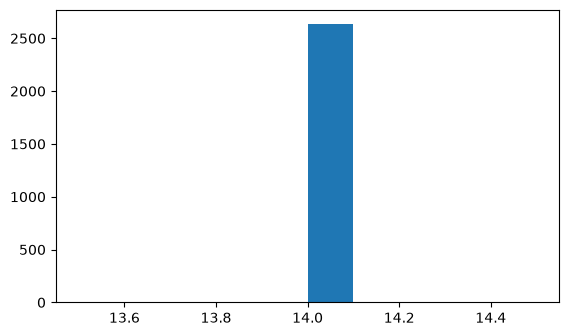

Минимум / медиана / максимум степеней: 14 14.0 14


In [15]:
degree = np.asarray((D > 0).sum(axis=1)).ravel()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.hist(degree, bins=10)
plt.show()

print("Минимум / медиана / максимум степеней:",
      degree.min(), np.median(degree), degree.max())

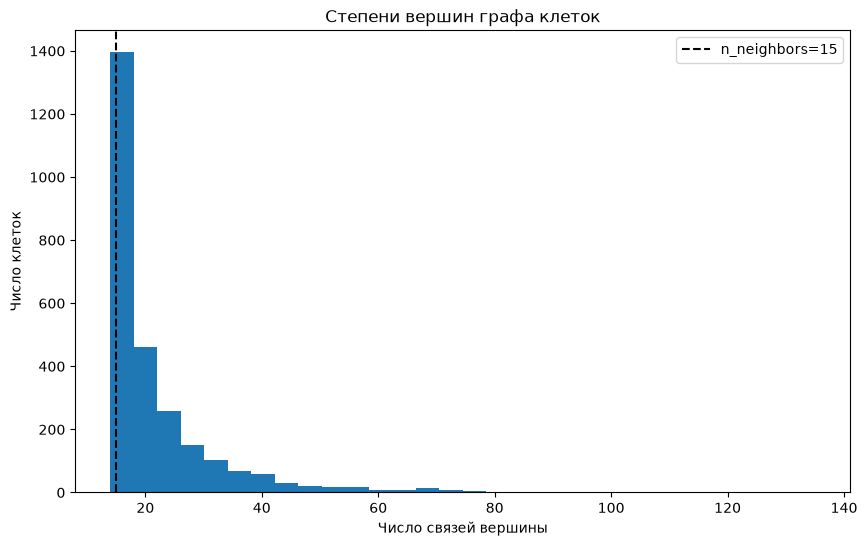

Число компонент связности: 1
Минимум / медиана / максимум степеней: 14 18.0 135


In [16]:
from scipy.sparse.csgraph import connected_components
degree = np.asarray((G > 0).sum(axis=1)).ravel()
components, labels_components = connected_components(G, directed=False)
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(degree, bins=30)
ax.axvline(15, ls="--", color="black", label="n_neighbors=15")
ax.set(xlabel="Число связей вершины", ylabel="Число клеток",
       title="Степени вершин графа клеток")
ax.legend()
plt.show()
print("Число компонент связности:", components)
print("Минимум / медиана / максимум степеней:",
      degree.min(), np.median(degree), degree.max())

# 3. Графовая кластеризация: Louvain → Leiden

**Кластеризация** — разбиение объектов на группы. Но «хорошая группа» должна иметь математическое определение.

- В методах типа k-means группа — набор точек, близких к общему центроиду.
- В графовых методах **сообщество** — группа вершин, которые связаны друг с другом сильнее, чем ожидалось бы при случайном соединении вершин по подходящей нулевой модели.

## 3.1. Модулярность: что оптимизирует алгоритм

Рассмотрим **ненаправленный граф** с матрицей весов $A=(A_{ij})$. Обозначим:

- $A_{ij}$ — вес ребра между вершинами $i$ и $j$;
- $k_i=\sum_j A_{ij}$ — взвешенная степень вершины $i$;
- $2m=\sum_i k_i$ — сумма весов рёбер, посчитанных по двум концам;
- $c_i$ — номер сообщества вершины $i$;
- $\mathbf{1}(c_i=c_j)$ равен единице, когда вершины в одной группе.

Одна из функций качества разбиения — **модулярность с параметром разрешения $\gamma$**:

$$
Q_{\gamma}=\frac{1}{2m}\sum_{i,j}
\left(A_{ij}-\gamma\frac{k_i k_j}{2m}\right)
\mathbf{1}(c_i=c_j).
$$

**Как понимать формулу:**

- $A_{ij}$ — наблюдаемый вес связи;
- $k_i k_j/(2m)$ — ожидаемый вес связи в модели случайного графа, сохраняющей ожидаемые степени вершин;
- в сумму попадают только пары вершин **из одной группы**;
- алгоритм пытается найти разбиение с **высоким значением $Q_\gamma$**.

$\gamma$ отвечает за масштаб: при большем $\gamma$ крупные сообщества сильнее «штрафуются», поэтому на практике часто появляются более мелкие кластеры. **Но число кластеров не обязано расти строго монотонно** из-за устройства графа и эвристической оптимизации.

## 3.2. Louvain и Leiden: чем они отличаются

**Louvain (2008):**

1. Стартует с отдельных сообществ (каждая вершина сама по себе).
2. По очереди переносит вершины между соседними сообществами, если растёт функция качества.
3. Объединяет сообщества в новые супервершины и повторяет оптимизацию.

**Проблема:** в отдельных случаях найденное сообщество может иметь плохую внутреннюю связность или даже быть несвязным.

**Leiden (2019)** добавляет **этап уточнения (refinement)** сообщества до агрегации. В результате алгоритм устраняет известную проблему несвязных сообществ Louvain и при сходимости предоставляет более сильные гарантии внутренней связности. Это **не означает**, что любой кластер Leiden биологически однороден.


Статья: [Traag, Waltman & van Eck, 2019 — From Louvain to Leiden](https://doi.org/10.1038/s41598-019-41695-z).

## 3.3. Leiden на PBMC 3k

Запустим Leiden несколько раз на **одном и том же графе**. Вызовы не используют координаты UMAP.

/var/folders/mz/btx2632133b3kr7fd6q6nw5c0000gn/T/ipykernel_13363/1703150331.py:1: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=0.2, key_added="leiden_0.2")
/var/folders/mz/btx2632133b3kr7fd6q6nw5c0000gn/T/ipykernel_13363/1703150331.py:2: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to

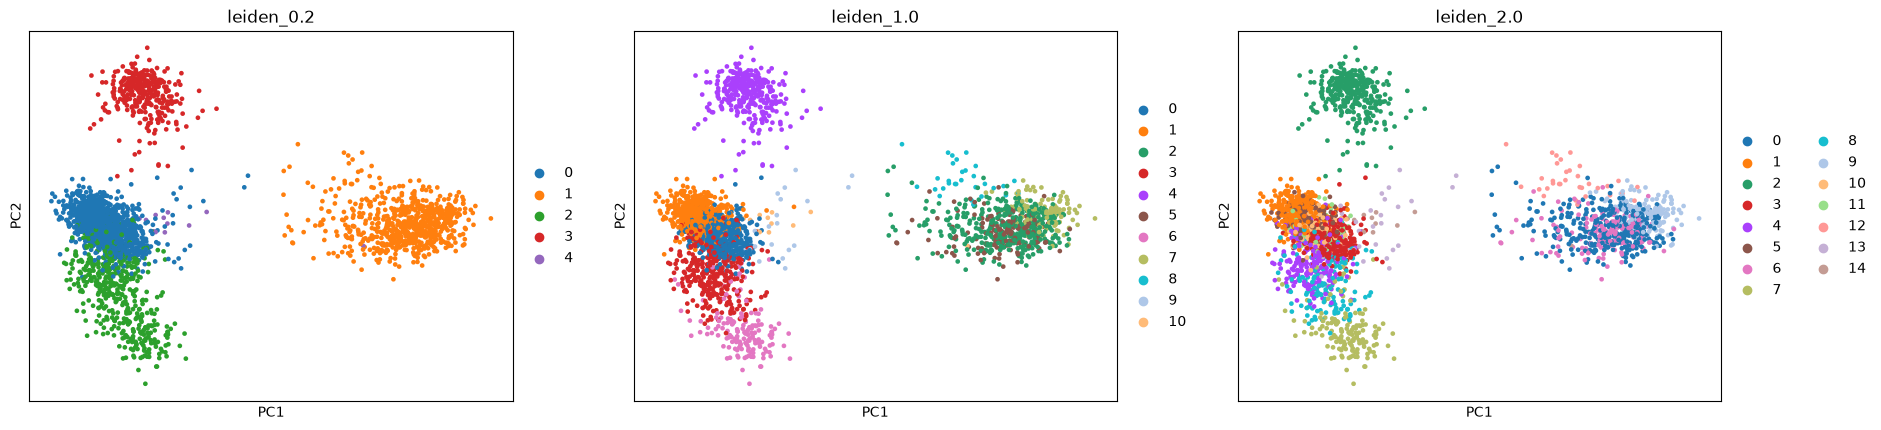

leiden_1.0
0     545
1     544
2     378
3     347
4     341
5     157
6     156
7     107
8      30
9      21
10     12
Name: count, dtype: int64


<Axes: xlabel='leiden_1.0'>

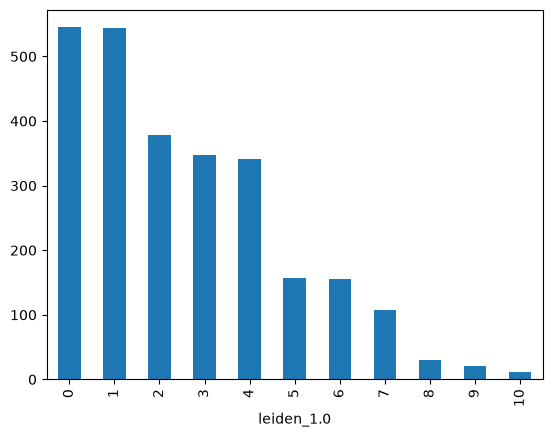

In [17]:
sc.tl.leiden(adata, resolution=0.2, key_added="leiden_0.2")
sc.tl.leiden(adata, resolution=1.0, key_added="leiden_1.0")
sc.tl.leiden(adata, resolution=2.0, key_added="leiden_2.0")

sc.pl.pca(
    adata,
    color=["leiden_0.2", "leiden_1.0", "leiden_2.0"],
    ncols=3
)
# Посмотрим, сколько получилось кластеров
print(adata.obs["leiden_1.0"].value_counts())
adata.obs["leiden_1.0"].value_counts().sort_index().plot.bar()

# 4. Переход из 30 измерений в два: t-SNE и UMAP 

## 4.1. t-SNE: сохраняем вероятности соседства

Идея t-SNE: описать, насколько клетка $j$ является соседом клетки $i$, **вероятностью**, а затем подобрать на плоскости такую картинку, чтобы отношения соседства были похожими.

В высокоразмерном пространстве PCA условные вероятности определяются расстояниями:

$$
p_{j\mid i}=\frac{\exp\!\left(-\frac{\|\mathbf x_i-\mathbf x_j\|^2}{2\sigma_i^2}\right)}
{\sum_{k\ne i}\exp\!\left(-\frac{\|\mathbf x_i-\mathbf x_k\|^2}{2\sigma_i^2}\right)},\quad p_{i\mid i}=0.
$$

Далее строятся симметричные $p_{ij}=(p_{j\mid i}+p_{i\mid j})/(2n)$.

На двумерной карте используются тяжёлые хвосты распределения Стьюдента:

$$
q_{ij}=\frac{(1+\|\mathbf y_i-\mathbf y_j\|^2)^{-1}}
{\sum_{k\ne \ell}(1+\|\mathbf y_k-\mathbf y_\ell\|^2)^{-1}}.
$$

Подбираем координаты $\mathbf y_i$, минимизируя **KL-дивергенцию**:

$$
D_{\mathrm{KL}}(P\|Q)=\sum_{i\ne j}p_{ij}\log\frac{p_{ij}}{q_{ij}}.
$$

**Смысл:** большие $p_{ij}$ «требуют», чтобы на карте $q_{ij}$ тоже были большими. Тяжёлые хвосты помогают разнести точки, которые не являются соседями.

`perplexity` управляет эффективным масштабом локального соседства: $\operatorname{Perp}(P_i)=2^{H(P_i)}$, где энтропия считается с логарифмом по основанию 2. Это **не точное число соседей** и не число кластеров.

## 4.2. UMAP: сохраняем взвешенное локальное соседство

UMAP начинает с соседей, строит **взвешенный граф** локального соседства и ищет координаты $\mathbf y_i$ на плоскости, при которых локальные связи остаются похожими.

В упрощённой записи направленные веса близости оцениваются как

$$
w_{j\mid i}=\exp\left[-\frac{\max\{0,d(i,j)-\rho_i\}}{\sigma_i}\right],
$$

где $\rho_i$ — локальное расстояние до ближайшего ненулевого соседа, $\sigma_i$ — локальный масштаб. Вес может затем объединяться с обратным $w_{i\mid j}$ по правилу

$$
w_{ij}=w_{j\mid i}+w_{i\mid j}-w_{j\mid i}w_{i\mid j}.
$$

На плоскости близость приближается функцией вида

$$
\hat w_{ij}=\frac{1}{1+a\|\mathbf y_i-\mathbf y_j\|^{2b}},
$$

где $a,b$ зависят от настроек формы кривой. **Идея функции потерь** — кросс-энтропия между весами связей исходного графа и весами на плоскости:

$$
\mathcal L=-\sum_{i<j}\left[
 w_{ij}\log\hat w_{ij}+(1-w_{ij})\log(1-\hat w_{ij})\right].
$$

Реальная оптимизация использует приближения, включая отрицательное семплирование несоседних пар. Формула выше описывает **математическую цель**, а не буквальный полный перебор всех пар в каждой итерации.

Параметры:

- **`n_neighbors`** (в `sc.pp.neighbors`) определяет масштаб исходных локальных отношений.
- **`min_dist`** (в `sc.tl.umap`) регулирует, насколько плотно точки могут располагаться на карте.
- **`random_state`** задаёт воспроизводимый случайный старт/другие случайные шаги алгоритма.

## Полезно посмотреть
* https://github.com/NikolayOskolkov/HowUMAPWorks/blob/master/HowUMAPWorks.ipynb   
* https://pair-code.github.io/understanding-umap/

# 5.Leiden + UMAP + t-SNE

**Цель:** выполнить обе визуализации для **одних и тех же клеток и одних и тех же меток Leiden**. Только так можно корректно сравнивать полученные картинки.

`sc.tl.umap()` использует уже построенный граф соседства. `sc.tl.tsne()` ниже явно использует первые 30 PC.

In [18]:
sc.tl.umap(adata, min_dist=0.3, random_state=42)

sc.tl.tsne(adata, use_rep="X_pca", n_pcs=30, perplexity=30, random_state=42)

In [19]:
print("UMAP:", adata.obsm["X_umap"].shape,
      "t-SNE:", adata.obsm["X_tsne"].shape)

UMAP: (2638, 2) t-SNE: (2638, 2)


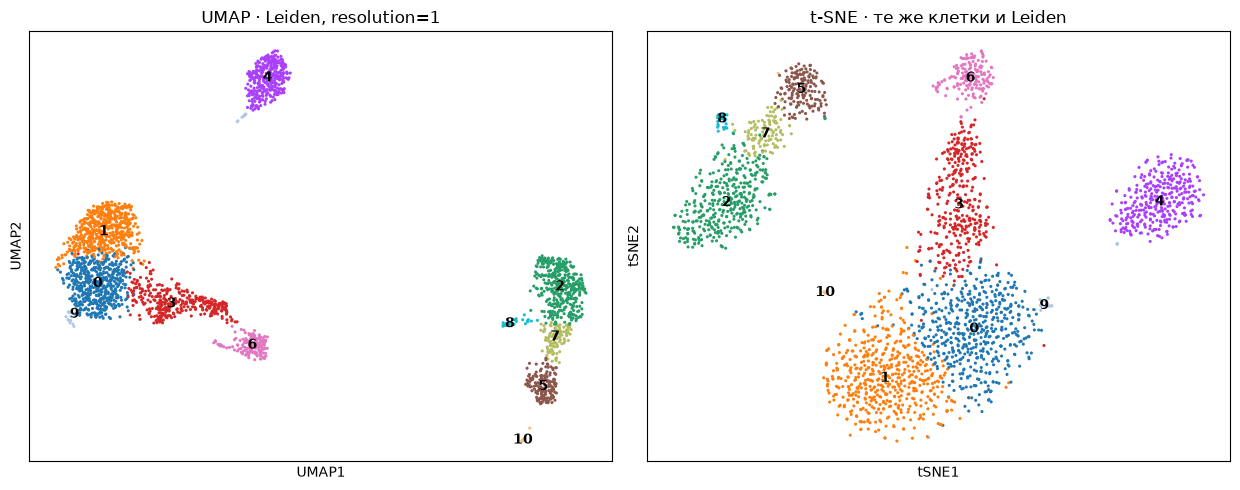

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.0))
sc.pl.umap(adata, color="leiden_1.0", legend_loc="on data",
           title="UMAP · Leiden, resolution=1", ax=axes[0], show=False, size=20)
sc.pl.tsne(adata, color="leiden_1.0", legend_loc="on data",
           title="t-SNE · те же клетки и Leiden", ax=axes[1], show=False, size=20)
plt.tight_layout()
plt.show()

## 5.1. Проверяем, что картинка не равна кластеризации

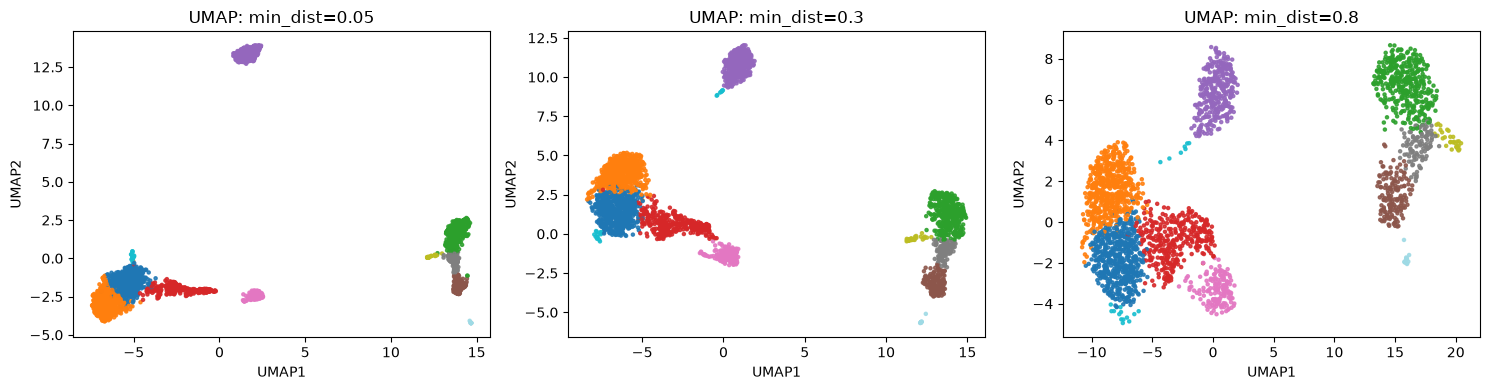

In [21]:
from copy import deepcopy
original_umap_params = deepcopy(adata.uns.get("umap", {}))
original_embedding = adata.obsm["X_umap"].copy()
original_labels = adata.obs["leiden_1.0"].copy()

embeddings = {0.3: original_embedding}
for value in (0.05, 0.8):
    sc.tl.umap(adata, min_dist=value, random_state=42)
    embeddings[value] = adata.obsm["X_umap"].copy()

adata.obsm["X_umap"] = original_embedding  # возвращаем основной UMAP
adata.uns["umap"] = original_umap_params  # и исходные параметры в AnnData
assert original_labels.equals(adata.obs["leiden_1.0"])

labels = adata.obs["leiden_1.0"].cat.codes.to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (value, xy) in zip(axes, sorted(embeddings.items())):
    ax.scatter(xy[:, 0], xy[:, 1], c=labels, cmap="tab20", s=5, alpha=0.85)
    ax.set(title=f"UMAP: min_dist={value}", xlabel="UMAP1", ylabel="UMAP2")
plt.tight_layout()
plt.show()

## 5.2. Проверка через биологию

Окрасим UMAP по известным генам-маркерам: `CD3D` (T-клетки), `MS4A1` (B-клетки), `NKG7` (NK-клетки), `LST1` (моноциты).

In [22]:
markers = [g for g in ["CD3D", "MS4A1", "NKG7", "LST1"] if g in adata.var_names]

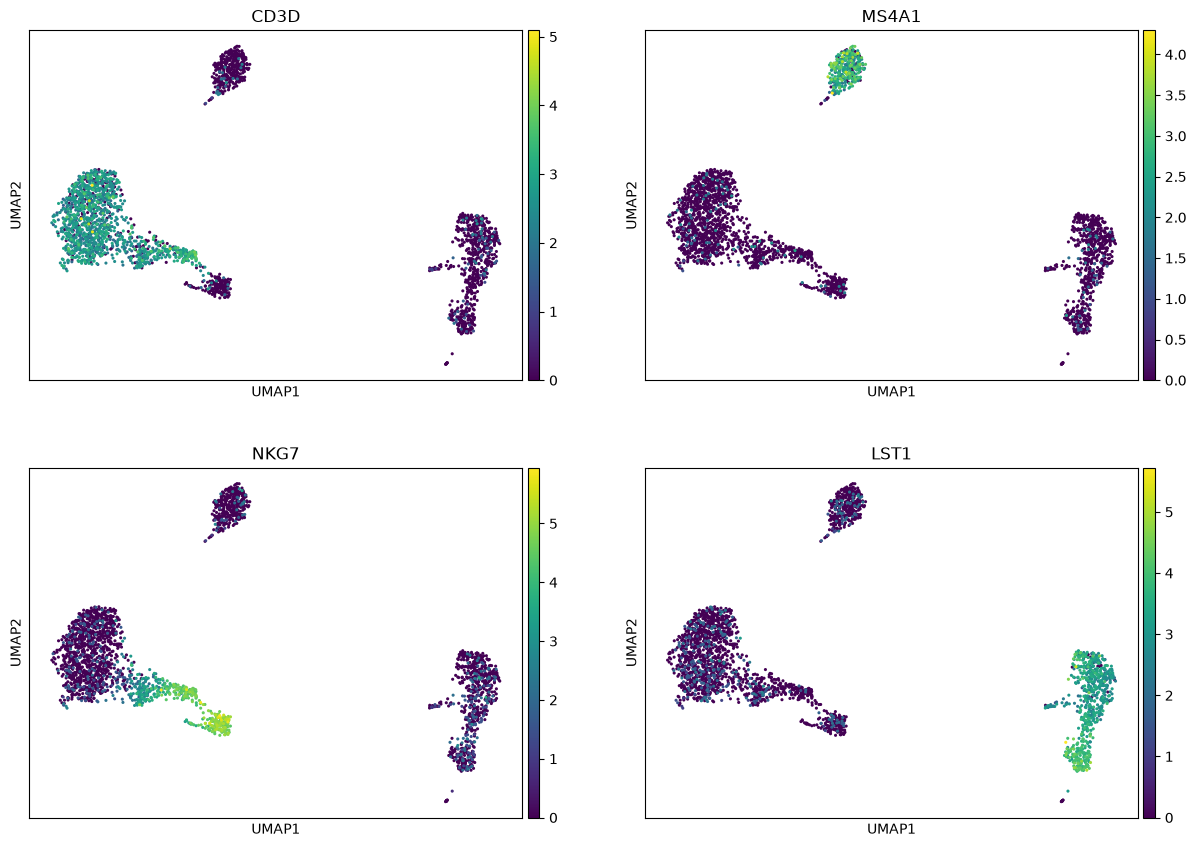

In [23]:
sc.pl.umap(adata, color=markers, ncols=2, size=20)

## 5.3. Сохраняем результаты для следующего занятия

В `.h5ad` сохраняются исходная матрица, `X_pca`, граф соседства, все варианты меток Leiden и основная визуализация `X_umap`/`X_tsne`. На следующем семинаре можно начать с аннотации кластеров, не повторяя вычисления.

In [24]:
result_path = Path("data/pbmc3k_after_clustering.h5ad")
adata.write_h5ad(result_path, compression="gzip")

# Самостоятельная работа: модулярность и анализ scRNA-seq

## Задание 1. Посчитать модулярность вручную

На рисунке показан **неориентированный невзвешенный граф из 9 вершин**. Рёбра внутри сообщества проведены сплошными линиями, между сообществами — пунктирными.

![Граф из 9 вершин](seminar6_modularity_graph.png)

Сообщества: **A = {1, 2, 3}**, **B = {4, 5, 6}**, **C = {7, 8, 9}**.

1. Посчитайте общее число рёбер графа `m`.
2. Для каждого сообщества найдите `l_c` — число рёбер, оба конца которых находятся внутри сообщества, и `d_c` — сумму степеней его вершин (включая внешние связи).
3. По формуле ниже вычислите **модулярность разбиения вручную**, показав промежуточные вычисления:

   $$Q=\sum_{c=1}^{3}\left(\frac{l_c}{m}-\left(\frac{d_c}{2m}\right)^2\right).$$

4. Объясните словами, зачем из доли внутренних рёбер вычитается второй член. Что показывает положительное значение `Q`? Является ли `Q` вероятностью?

## Задание 2. Самостоятельный анализ клеток в Scanpy

**Выберите один** набор 10x Genomics (PBMC 3k не использовать):

- [Клетки сердца эмбриона мыши E18 (~1011 клеток)](https://www.10xgenomics.com/datasets/1-k-heart-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0)
- [Клетки головного мозга эмбриона мыши E18 (~1301 клетка)](https://www.10xgenomics.com/datasets/1-k-brain-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0)
- [Клетки селезёнки мыши (~1119 клеток)](https://www.10xgenomics.com/datasets/splenocytes-from-c-57-bl-6-mice-1-k-cells-v-2-2-standard-4-0-0)

На странице набора загрузите **Feature / cell matrix HDF5 (filtered)** (для селезёнки — матрицу **Gene Expression**, а не V(D)J). Это счётчики UMI для баркодов, уже отобранных Cell Ranger; исходные пустые капли в эту матрицу не входят.

```python
import scanpy as sc
adata = sc.read_10x_h5("путь/к/скачанному_файлу.h5")
adata.var_names_make_unique()
```

**Проведите анализ**, используя методы Scanpy, изученные на семинарах:

1. **QC.** Посчитайте и покажите распределения количества UMI (`total_counts`), обнаруженных генов (`n_genes_by_counts`) и доли митохондриальных счётчиков (`pct_counts_mt`). Выберите пороги фильтрации клеток и генов, примените их и **объясните почему выбрали именно эти значения**. Укажите, сколько клеток осталось.
2. **Нормализация и HVG.** Выполните нормализацию, `log1p` и отбор высоковариабельных генов. Укажите число HVG и объясните, зачем их отбирают и почему выбранное количество разумно.
3. **PCA.** Постройте PCA. Выберите число главных компонент для дальнейшего анализа; объясните выбор, используя график доли объяснённой дисперсии.
4. **Граф и Leiden.** Постройте граф соседей, выполните кластеризацию Leiden. Укажите `n_neighbors`, `n_pcs`, `resolution`, число получившихся кластеров и число клеток в них. Объясните выбранные параметры.
5. **UMAP и t-SNE.** Постройте обе визуализации, раскрасив точки по меткам Leiden. Также раскрасьте PCA или UMAP по одной QC-метрике и по **двум выбранным известным генам**, если они есть в данных. Опишите, что видно и какие выводы сделать нельзя.
6. **Биологический вывод.** По нескольким предложениям объясните, какие клеточные популяции **предположительно** присутствуют в выбранной ткани. Обоснуйте предположение экспрессией выбранных генов; не называйте кластеры достоверно определёнными клеточными типами.

**Разрешено:** стандартные функции Scanpy для QC, фильтрации, нормализации, HVG, PCA, графа соседей, Leiden, UMAP и t-SNE; окраска графиков по кластерам, QC-метрикам и **заданным вручную** генам.

**Не использовать:** `sc.tl.rank_genes_groups`, `sc.tl.score_genes`, методы автоматической аннотации или другие ещё не изученные методы. Подбор генов можно сделать по литературе, без автоматического поиска маркеров.

**Что сдавать:** число и расчёт модулярности; Jupyter-ноутбук с анализом одного набора данных, графиками, числом клеток до/после QC, параметрами и краткими объяснениями сделанных решений. Не требуется получить «правильное» число кластеров.


### Выбор датасета

Выбран набор **«Клетки головного мозга эмбриона мыши E18»** (10x Genomics, Single Cell 3' v3, ~1301 клетка):
https://www.10xgenomics.com/datasets/1-k-brain-cells-from-an-e-18-mouse-v-3-chemistry-3-standard-3-0-0

Скачан файл `neuron_1k_v3_filtered_feature_bc_matrix.h5` (Feature / cell matrix HDF5, filtered). Ниже код ищет его сначала в локальной папке `data/` (куда его стоит положить при самостоятельном запуске), а если не находит — использует путь, по которому файл был загружен для проверки этого ноутбука.

In [25]:
from pathlib import Path
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

mouse_h5_path = Path("/Users/veronikaaksinina/Downloads/neuron_1k_v3_filtered_feature_bc_matrix.h5")
if not mouse_h5_path.exists():
    mouse_h5_path = Path("/mnt/user-data/uploads/neuron_1k_v3_filtered_feature_bc_matrix.h5")

mouse = sc.read_10x_h5(mouse_h5_path)
mouse.var_names_make_unique()
mouse

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


AnnData object with n_obs × n_vars = 1301 × 31053
    var: 'gene_ids', 'feature_types', 'genome'
    layers: None (.X)

#### 1. QC

Мышиные митохондриальные гены в отличие от человеческих (`MT-...`) обозначаются префиксом `mt-...` (например, `mt-Nd1`, `mt-Co1`), поэтому маску для `pct_counts_mt` нужно строить по-другому, чем в семинаре с PBMC.

Найдено митохондриальных генов: 13


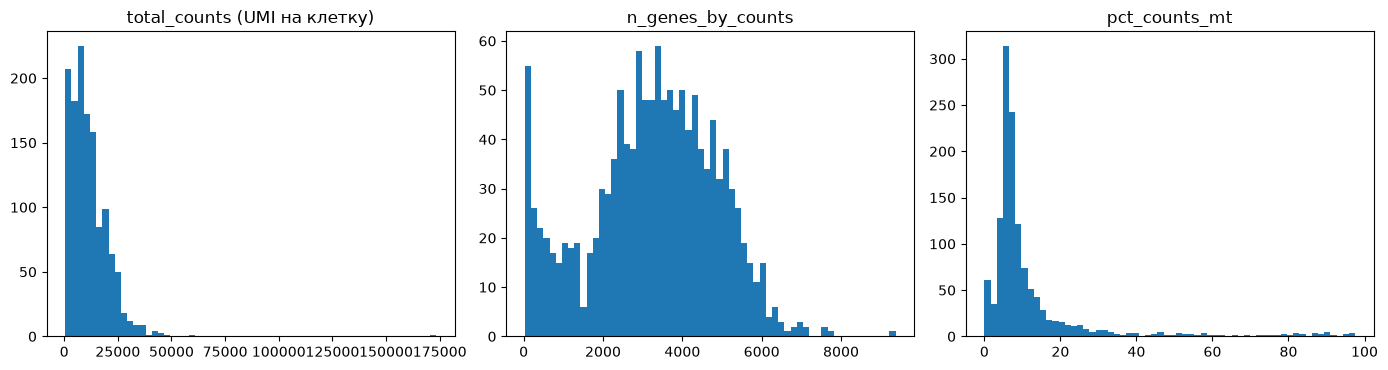

,total_counts,n_genes_by_counts,pct_counts_mt
count,1301.000000,1301.000000,1301.000000
mean,11468.593750,3244.036895,12.257775
std,9340.619141,1606.013468,15.889544
min,500.000000,29.000000,0.000000
25%,5333.000000,2258.000000,5.505189
50%,9744.000000,3356.000000,7.163898
75%,15821.000000,4394.000000,11.408631
max,173276.000000,9374.000000,97.527199


In [26]:
mouse.var["mt"] = mouse.var_names.str.startswith("mt-")
sc.pp.calculate_qc_metrics(mouse, qc_vars=["mt"], inplace=True)
print("Найдено митохондриальных генов:", mouse.var["mt"].sum())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(mouse.obs["total_counts"], bins=60)
axes[0].set_title("total_counts (UMI на клетку)")
axes[1].hist(mouse.obs["n_genes_by_counts"], bins=60)
axes[1].set_title("n_genes_by_counts")
axes[2].hist(mouse.obs["pct_counts_mt"], bins=60)
axes[2].set_title("pct_counts_mt")
plt.tight_layout()
plt.show()

mouse.obs[["total_counts", "n_genes_by_counts", "pct_counts_mt"]].describe()

**Почему выбраны такие пороги.**

Матрица уже отфильтрована Cell Ranger (это *filtered* matrix), поэтому пустых капель в ней почти нет, но внутри всё равно остаются низкокачественные и, возможно, дублетные баркоды:

- **`min_genes=200`** — стандартный нижний порог (как и в семинаре с PBMC): отсекает баркоды с совсем малым числом детектированных генов (таких 58 из 1301, 1-й перцентиль по `n_genes` — всего 45 генов) — это, скорее всего, "пустые"/почти пустые капли или сильно деградировавшая РНК, а не настоящие клетки.
- **`n_genes_by_counts < 7000`** — верхний порог против вероятных дублетов. Основная масса клеток укладывается в 2000–6500 генов (95-й перцентиль ≈ 5640), но у 6 баркодов обнаружено более 7000 генов и до 173 тыс. UMI (это в ~15–18 раз больше медианы 9744 UMI) — характерная картина для двух слипшихся клеток, которые стоит убрать до кластеризации.
- **`pct_counts_mt < 20`** — порог по доле митохондриальных ридов заметно мягче, чем у PBMC в семинаре (`<5%`). У нервной ткани эмбриона базовый уровеньमitохондриальной экспрессии выше, чем у клеток крови (медиана `pct_counts_mt` в этом наборе — 7.2%, а не ~2–3%, как у PBMC), поэтому единый для всех тканей порог в 5% отрезал бы слишком много нормальных нейронов. 20% — компромисс: отсекает явно умирающие/повреждённые при диссоциации клетки (правый хвост распределения уходит вплоть до 97%), но не трогает основную массу клеток.
- **`filter_genes(min_cells=3)`** — как и в семинаре, убирает гены, которые не детектированы практически ни в одной клетке и только добавляют шум/разреженность.

In [27]:
print("Клеток до фильтрации:", mouse.n_obs)

sc.pp.filter_cells(mouse, min_genes=200)
print("После min_genes=200:", mouse.n_obs)

mouse = mouse[
    (mouse.obs["n_genes_by_counts"] < 7000) &
    (mouse.obs["pct_counts_mt"] < 20)
].copy()
print("После n_genes_by_counts<7000 и pct_counts_mt<20:", mouse.n_obs)

sc.pp.filter_genes(mouse, min_cells=3)
print("Генов после filter_genes(min_cells=3):", mouse.n_vars)

mouse

Клеток до фильтрации: 1301
После min_genes=200: 1243
После n_genes_by_counts<7000 и pct_counts_mt<20: 1111
Генов после filter_genes(min_cells=3): 15514


AnnData object with n_obs × n_vars = 1111 × 15514
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: None (.X)

#### 2. Нормализация и HVG

`normalize_total` приводит суммарное число UMI в каждой клетке к общему масштабу (убирает технический эффект разной глубины секвенирования/размера клетки), `log1p` сжимает динамический диапазон экспрессии, приближая распределение к более симметричному и уменьшая влияние единичных очень сильно экспрессированных генов. Высоковариабельные гены (HVG) отбираются *до* нормализации по "сырым" счётчикам (`flavor="seurat_v3"`, слой `counts`) — этот метод учитывает зависимость дисперсии от среднего и устойчивее к шуму редких генов, чем отбор по дисперсии уже прологарифмированных данных.

In [28]:
mouse.layers["counts"] = mouse.X.copy()

sc.pp.highly_variable_genes(
    mouse, layer="counts", flavor="seurat_v3", n_top_genes=2000
)
sc.pp.normalize_total(mouse, target_sum=1e4)
sc.pp.log1p(mouse)

print("HVG отобрано:", int(mouse.var["highly_variable"].sum()), "из", mouse.n_vars, "генов")

HVG отобрано: 2000 из 15514 генов


**Почему 2000 HVG.** Это та же величина, что и в семинаре на PBMC, и она разумна и здесь: 2000 генов — это около 13% от 15514 генов, прошедших фильтр по `min_cells=3`. Этого достаточно, чтобы захватить гены, различающие как крупные линии (нейроны/глия/прогениторы), так и более тонкие подтипы, но при этом отсечь десятки тысяч низкоинформативных/шумных генов, которые только замедлили бы PCA и смазали структуру в графе соседей.

#### 3. PCA

/var/folders/mz/btx2632133b3kr7fd6q6nw5c0000gn/T/ipykernel_13363/1911400844.py:5: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


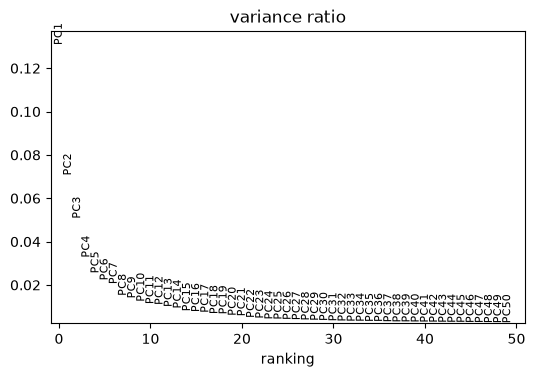

Доля дисперсии по первым 10 PC (%): [13.07  7.05  5.06  3.26  2.54  2.21  2.04  1.5   1.38  1.23]
  10 PC ->  39.3% суммарной объяснённой дисперсии
  15 PC ->  44.2% суммарной объяснённой дисперсии
  20 PC ->  47.6% суммарной объяснённой дисперсии
  25 PC ->  49.9% суммарной объяснённой дисперсии
  30 PC ->  51.7% суммарной объяснённой дисперсии


In [29]:
sc.tl.pca(mouse, n_comps=50, mask_var="highly_variable", random_state=42)

sc.pl.pca_variance_ratio(mouse, n_pcs=50, log=False, show=False)
plt.gcf().set_size_inches(6, 3.8)
plt.tight_layout()
plt.show()

vr = mouse.uns["pca"]["variance_ratio"]
cum = np.cumsum(vr)
print("Доля дисперсии по первым 10 PC (%):", np.round(vr[:10] * 100, 2))
for n in (10, 15, 20, 25, 30):
    print(f"  {n:2d} PC -> {cum[n-1]*100:5.1f}% суммарной объяснённой дисперсии")

**Выбор числа PC: 20.** Первая компонента объясняет заметно больше дисперсии, чем остальные (13.1%), затем вклад быстро падает (PC2 — 7.1%, PC3 — 5.1%) и к 10–12-й компоненте выходит на пологое плато (~1.1–1.2% на компоненту). После ~20-й PC каждая следующая компонента добавляет уже меньше 0.6% — дальнейшие PC с высокой вероятностью содержат в основном шум. В семинаре для PBMC (2700+ клеток) использовали 30 PC; здесь клеток меньше (1111 после QC), поэтому разумно взять число PC поменьше, чтобы не подгонять соседей под шумовые направления — отсюда `n_pcs=20`.

#### 4. Граф соседей и Leiden

In [30]:
sc.pp.neighbors(
    mouse,
    n_neighbors=15,
    n_pcs=20,
    metric="euclidean",
    method="umap",
    random_state=42,
)

for res in (0.3, 0.5, 0.8):
    sc.tl.leiden(mouse, resolution=res, key_added=f"leiden_{res}", random_state=42)
    vc = mouse.obs[f"leiden_{res}"].value_counts().sort_index()
    print(f"resolution={res}: {mouse.obs[f'leiden_{res}'].nunique()} кластеров, размеры: {vc.tolist()}")

/var/folders/mz/btx2632133b3kr7fd6q6nw5c0000gn/T/ipykernel_13363/163495916.py:11: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(mouse, resolution=res, key_added=f"leiden_{res}", random_state=42)
/var/folders/mz/btx2632133b3kr7fd6q6nw5c0000gn/T/ipykernel_13363/163495916.py:11: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` mus

resolution=0.3: 9 кластеров, размеры: [237, 226, 163, 119, 115, 84, 80, 79, 8]
resolution=0.5: 12 кластеров, размеры: [162, 161, 160, 133, 119, 104, 80, 60, 44, 40, 40, 8]
resolution=0.8: 15 кластеров, размеры: [146, 119, 103, 102, 102, 98, 87, 85, 58, 58, 52, 44, 40, 9, 8]


/var/folders/mz/btx2632133b3kr7fd6q6nw5c0000gn/T/ipykernel_13363/163495916.py:11: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(mouse, resolution=res, key_added=f"leiden_{res}", random_state=42)


**Параметры.**

- **`n_neighbors=15`** — то же значение, что и в семинаре; для выборки такого размера (~1100 клеток) это стандартный баланс между локальной (мелкие подтипы) и более общей структурой графа.
- **`n_pcs=20`** — согласовано с выбором числа компонент на шаге PCA выше.
- **`resolution=0.8`** — выбрана после сравнения трёх значений: при `0.3` получаются всего 9 крупных кластеров, и внутри них явно смешиваются клетки с очень разным профилем маркеров (прогениторы и уже дифференцирующиеся нейроны в одной группе); при `0.8` получается 15 кластеров размером от 8 до 146 клеток, и дополнительно отделяются два маленьких, но биологически осмысленных кластера редких типов клеток (по экспрессии маркеров ниже — микроглия и эритроциты, по 8–9 клеток), которые при `0.3`–`0.5` тонут внутри более крупных групп. Дальнейшее увеличение resolution в основном дробит уже и так крупные нейрональные кластеры, не добавляя новой интерпретируемой структуры, поэтому `0.8` — разумный рабочий выбор (это не "единственно верное" число кластеров, как и отмечено в задании).

#### 5. UMAP и t-SNE

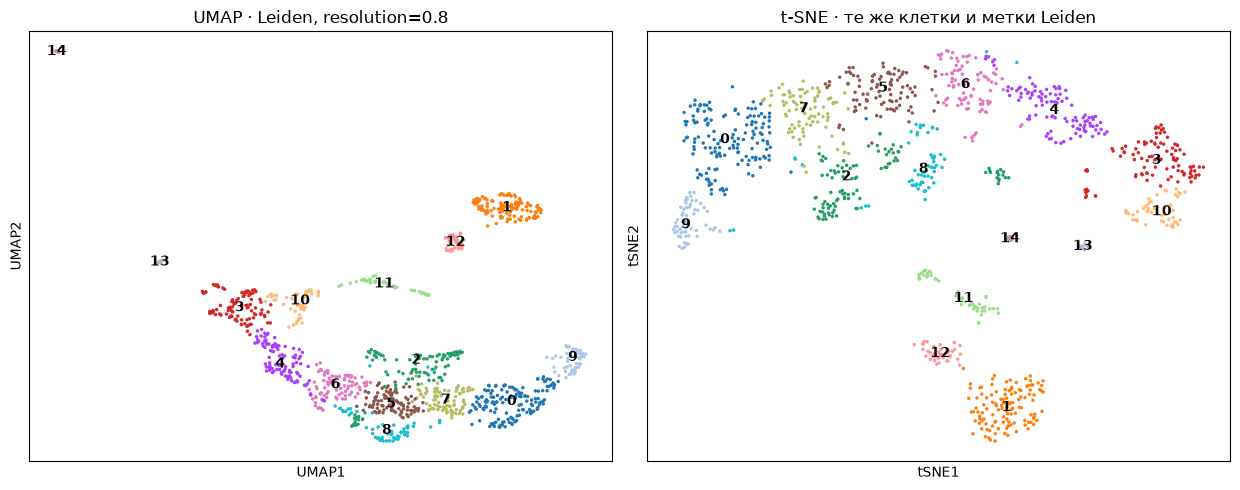

In [31]:
sc.tl.umap(mouse, min_dist=0.3, random_state=42)
sc.tl.tsne(mouse, use_rep="X_pca", n_pcs=20, perplexity=30, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.0))
sc.pl.umap(mouse, color="leiden_0.8", legend_loc="on data",
           title="UMAP · Leiden, resolution=0.8", ax=axes[0], show=False, size=25)
sc.pl.tsne(mouse, color="leiden_0.8", legend_loc="on data",
           title="t-SNE · те же клетки и метки Leiden", ax=axes[1], show=False, size=25)
plt.tight_layout()
plt.show()

Для проверки — та же UMAP-проекция, раскрашенная по одной QC-метрике (`pct_counts_mt`, чтобы убедиться, что кластеры не являются артефактом качества клеток) и по двум выбранным по литературе маркерным генам: **`Sox2`** (нейральные стволовые клетки / радиальная глия — ранние предшественники) и **`Neurod6`** (коммитированные/дифференцирующиеся возбуждающие нейроны). Дополнительно показаны ещё два маркера для более полной картины: **`Gad2`** (тормозные ГАМК-ергические нейроны) и **`Cx3cr1`** (микроглия — немного клеток, не относящихся к нейрональной линии).

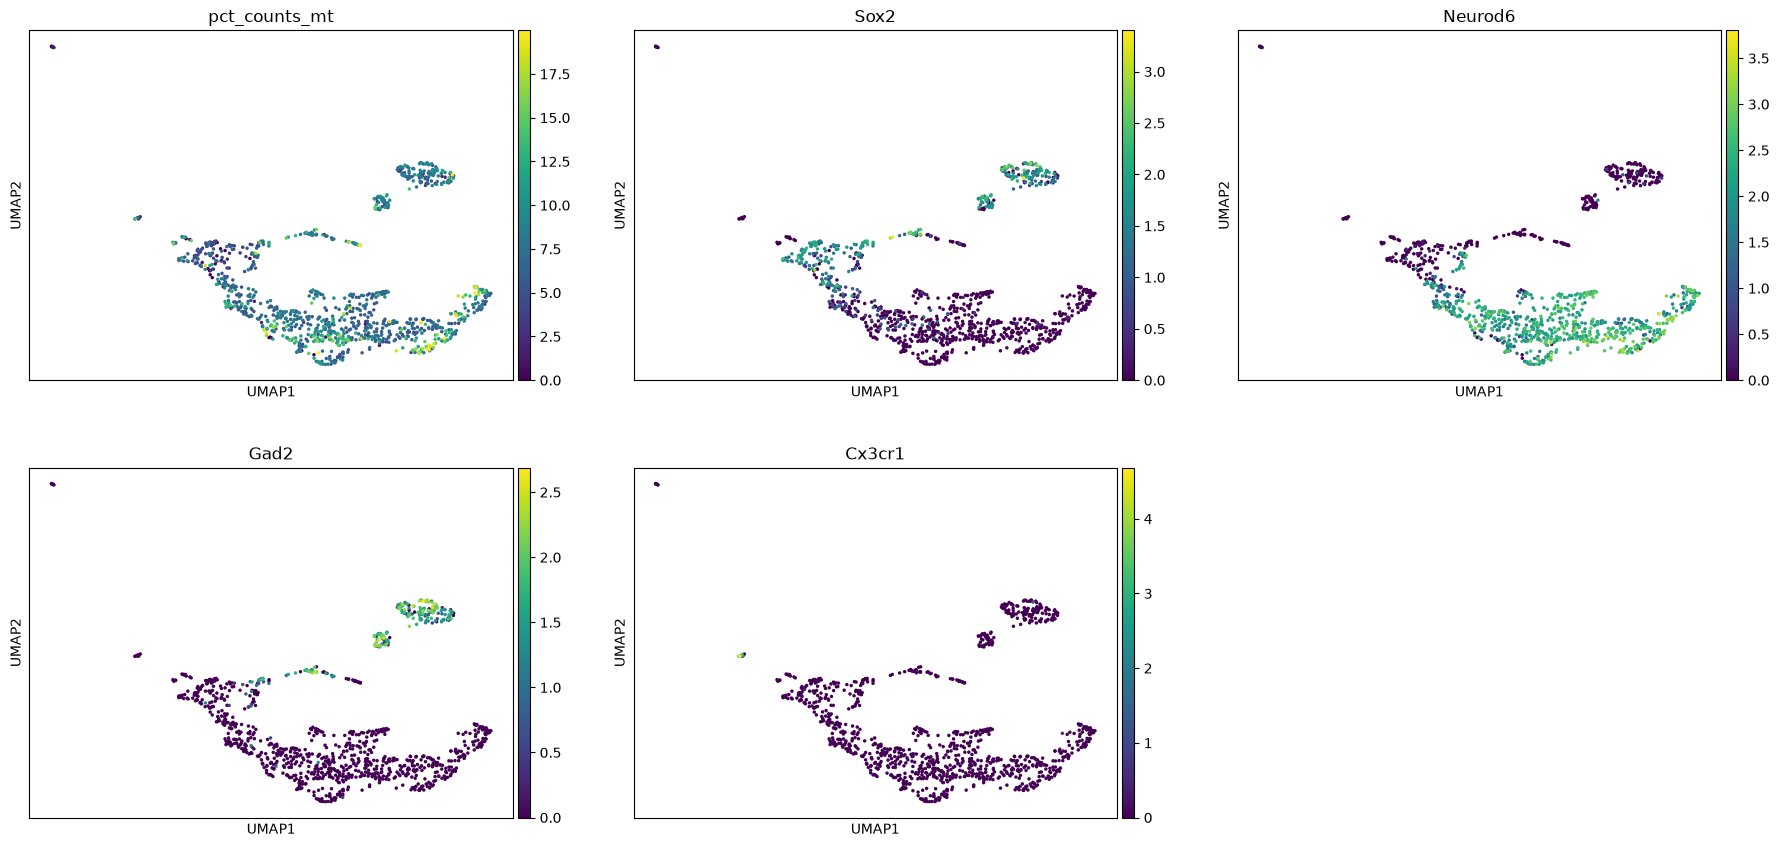

In [32]:
sc.pl.umap(
    mouse,
    color=["pct_counts_mt", "Sox2", "Neurod6", "Gad2", "Cx3cr1"],
    ncols=3,
    size=25,
)

**Что видно.** Облако клеток на UMAP не распадается на полностью изолированные "острова" — скорее, большая часть клеток образует непрерывный шлейф с градиентом: на одном конце клетки с высоким `Sox2` и низким `Neurod6` (предшественники), дальше — зона смешанной экспрессии, и на другом конце — клетки с высоким `Neurod6` и практически нулевым `Sox2` (дифференцированные возбуждающие нейроны). Это согласуется с тем, что в развивающемся мозге клетки на самом деле проходят непрерывный процесс дифференцировки, а не распределены по жёстко заданным дискретным типам. `Gad2`-позитивные клетки образуют отдельное, не самое большое скопление — предполагаемые тормозные нейроны. `Cx3cr1` экспрессирован лишь в единичных клетках, которые на UMAP образуют маленькое обособленное пятно в стороне от основного "нейронального" облака — это ожидаемо для немногочисленной примеси иммунных клеток. График по QC-метрике (`pct_counts_mt`) не показывает явной корреляции с кластерами — высокая или низкая доля митохондриальных ридов не привязана к какому-то одному кластеру, то есть кластеризация, скорее всего, отражает биологию, а не артефакт качества.

**Что нельзя утверждать по этим картинкам.** Расстояния и форма "рукавов" на UMAP/t-SNE не являются точной мерой биологического расстояния между клетками — близость на графике не доказывает общую функцию, а удалённость не доказывает, что это разные типы клеток (это лишь низкоразмерная аппроксимация структуры графа соседей). Два алгоритма дают разную форму картинки для одних и тех же клеток и одних и тех же меток Leiden (сравните панели выше) — значит, сама по себе форма кластера на конкретной проекции не несёт объективного смысла, важны только сами метки и относительное соседство. Наконец, окраска по 1–2 генам — не идентификация типа клетки: один маркер может экспрессироваться в нескольких разных типах клеток, и однозначный вывод о клеточной идентичности без систематического анализа множества маркеров (который в этом задании намеренно не делается) делать нельзя.

#### 6. Биологический вывод

Судя по экспрессии нескольких заранее выбранных по литературе маркеров (без автоматического поиска), в образце предположительно присутствует смесь клеток на разных стадиях нейрогенеза эмбрионального мозга мыши E18, что ожидаемо для этой ткани и возраста:

- часть кластеров с высоким `Sox2`/`Pax6`/`Vim` и низкими нейрональными маркерами, вероятно, соответствует нейральным предшественникам/радиальной глии
- ещё один кластер с высоким `Eomes` при умеренном `Sox2` может соответствовать промежуточным (базальным) предшественникам — переходной стадии между радиальной глией и нейронами;
- большая часть клеток с высоким `Neurod6`/`Dcx` (и у части — заметным `Tbr1`/`Rbfox3`) — вероятно, дифференцирующиеся и частично созревающие возбуждающие (глутаматергические) нейроны** на разных стадиях созревания;
- один-два кластера с `Gad1`/`Gad2` (у части — вместе с `Reln`) — предположительно ГАМК-ергические (тормозные) нейроны/их предшественники;
- отдельный маленький кластер с `Cx3cr1` — вероятно, немногочисленная примесь микроглии (не нейрональная линия, резидентные иммунные клетки мозга);
- отдельный маленький кластер с очень высоким `Hba-a1` — скорее всего, примесь эритроцитов (остатки крови в образце, а не клетки мозга как такового).

Эти предположения основаны только на экспрессии вручную выбранных генов-кандидатов на уровне кластеров и не являются достоверной аннотацией типов клеток — для неё потребовались бы более систематический анализ маркеров (например, `rank_genes_groups`, намеренно не использованный в этом задании), сверка с референсными атласами и/или ортогональные данные.